# 02 · Barcode region detection (paper Sec. 2.2 Step 1, Fig. *pipeline*)

How the app finds the four label corners inside the capture ROI:

1. **Colour quantization** in HSV into red / white / black (reduces sensitivity to lighting).
2. **Red blocks**: a 2×2 window (stride 1) is red if at least 3 of its 4 pixels are red.
3. **Corners**: in a band at the top and one at the bottom of the ROI, the red block closest to each ROI corner.

`visioncrack.detection` is a line-by-line port of the app's Dart code (`detection.dart`).
The last section checks that it finds the **same corners the phone recorded** for every Table 1 capture.

| | |
|---|---|
| **Inputs** | `data/raw/table1_et/` |
| **Outputs** | `results/figures/fig_pipeline.png`, `results/tables/corners_python_vs_app.csv` |
| **Runtime** | ~10 s |

In [ ]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import visioncrack as vc
from visioncrack import io
np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.width', 200)
print('visioncrack', vc.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
FIG = io.results_dir('figures'); TAB = io.results_dir('tables')

visioncrack 0.1.0 | numpy 2.2.6 | pandas 2.3.0


In [ ]:
from visioncrack import detection as det
caps, _ = vc.load_table1()
roi = vc.preview_roi((2160, 3840), (430, 932))
x0, y0, x1, y1 = roi.xyxy
img = vc.read_rgb(caps.path[0])
crop = img[y0:y1, x0:x1]
labels = det.quantize(crop)
c = det.find_corners(crop)
print('corners (TL, TR, BL, BR):', c.as_array().tolist())

corners (TL, TR, BL, BR): [[1, 3], [783, 17], [1, 477], [782, 476]]


> **Paper vs. app.** The manuscript says the ROI is split into top and bottom *halves*.
> The app searches **64-px bands** at the top and bottom instead (`detection.BAND_PX`).
> The port follows the app. The manuscript text should be aligned with it (or the other way round).

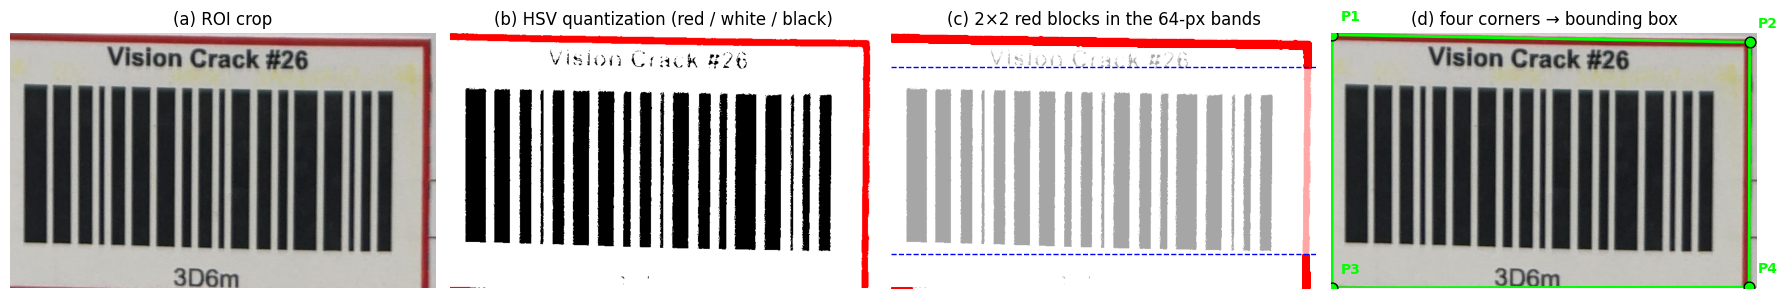

In [ ]:
B = det.BAND_PX
top_blocks = det.red_blocks(labels[:B] == 1)
bot_blocks = det.red_blocks(labels[-B:] == 1) + [0, roi.h - B]

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
ax[0].imshow(crop); ax[0].set_title('(a) ROI crop')
ax[1].imshow(det.quantized_rgb(labels)); ax[1].set_title('(b) HSV quantization (red / white / black)')
ax[2].imshow(det.quantized_rgb(labels), alpha=.35)
ax[2].scatter(*top_blocks.T, s=1, c='red'); ax[2].scatter(*bot_blocks.T, s=1, c='red')
for yy in (B, roi.h - B): ax[2].axhline(yy, color='blue', ls='--', lw=1)
ax[2].set_title(f'(c) 2×2 red blocks in the {B}-px bands')
ax[3].imshow(crop)
q = c.as_array()[[0, 1, 3, 2, 0]]
ax[3].plot(q[:, 0], q[:, 1], 'lime', lw=2)
for (px, py), n in zip(c.as_array(), ['P1', 'P2', 'P3', 'P4']):
    ax[3].scatter(px, py, s=60, c='lime', edgecolor='k', zorder=3)
    ax[3].annotate(n, (px, py), color='lime', weight='bold', xytext=(6, 10), textcoords='offset points')
ax[3].set_title('(d) four corners → bounding box')
for a in ax: a.axis('off')
plt.tight_layout(); plt.savefig(FIG / 'fig_pipeline.png', dpi=200); plt.show()

## Python port vs. the corners recorded by the phone (all 10 Table 1 captures)

In [ ]:
rows = []
for p, app_bb in zip(caps.path, caps.bbox):
    im = vc.read_rgb(p)[y0:y1, x0:x1]
    py_bb = det.find_corners(im).as_array()
    rows.append({'image': p.name, 'max_abs_diff_px': int(np.abs(py_bb - app_bb).max()),
                 'python': py_bb.tolist(), 'app': app_bb.tolist()})
cmp = pd.DataFrame(rows)
cmp.to_csv(TAB / 'corners_python_vs_app.csv', index=False)
display(cmp[['image', 'max_abs_diff_px']])
assert cmp.max_abs_diff_px.max() <= 2
print('✓ Python port matches the phone within', cmp.max_abs_diff_px.max(), 'px '
      '(the phone ran on the live camera frame, the PNG is the saved capture)')

,image,max_abs_diff_px
0,1752392841.png,1
1,1752392881.png,1
2,1752392896.png,2
3,1752392902.png,2
4,1752392907.png,2
5,1752392918.png,1
6,1752392931.png,1
7,1752392968.png,1
8,1752392981.png,2
9,1752392987.png,0


✓ Python port matches the phone within 2 px (the phone ran on the live camera frame, the PNG is the saved capture)
